# MLT Homework Assignment #4
Danil Nedorezov
Data: https://drive.google.com/drive/folders/1KpT0oBIb3aDaBtjf7Hs4WAUPoFEpbsYr?usp=sharing

**Task 1:**
1. Build and fit CNN with 3 convolutional layers for binary classification
2. Evaluate accuracy on test data
3. Plot the graphs for Loss(number_of_epochs) and Accuracy(number_of_epochs)

**Task 2:**
1. Build and fit a Transfer Learning model using pre-trained VGG16 weights from torchvision.models
2. Do the same with another available pre-trained model from torchvision.models
3. Evaluate accuracy on test data for p.1 and p.2
4. Plot the graphs for Loss(number_of_epochs) and Accuracy(number_of_epochs)
5. Check the performance of the model on a custom image of a cat or a dog, and develop the inference
   function for the best algorithm

**Task 3 (contest, optional):** train a classifier with the highest possible accuracy **without any
pre-trained weights**.

First, let's load all the necessary functions:

In [ ]:
import os
import time
import urllib.request

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

import matplotlib.pyplot as plt
from PIL import Image

SEED = 1
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

%matplotlib inline

In [ ]:
IN_COLAB = os.path.exists("/content")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive/")

    os.system('cp "/content/drive/My Drive/Cats_and_Dogs.zip" "/content/Cats_and_Dogs.zip"')

    import zipfile
    archive, destination = "/content/Cats_and_Dogs.zip", "/content/Cats_and_Dogs"
    with zipfile.ZipFile(archive, "r") as zf:
        for member in zf.namelist():
            parts = member.split("/")
            if "Cats_and_Dogs" not in parts:
                continue
            tail = parts[parts.index("Cats_and_Dogs") + 1:]
            if not tail:
                continue
            target = os.path.join(destination, *tail)
            if member.endswith("/"):
                os.makedirs(target, exist_ok=True)
            else:
                os.makedirs(os.path.dirname(target), exist_ok=True)
                with zf.open(member) as src, open(target, "wb") as dst:
                    dst.write(src.read())
    print("Extraction completed!")
    DATA_ROOT = "/content/Cats_and_Dogs"
else:
    DATA_ROOT = "data/Cats_and_Dogs"

print("data root:", DATA_ROOT)
print("content:", sorted(os.listdir(DATA_ROOT)))

data root: data/Cats_and_Dogs
content: ['test', 'train', 'val']


In [ ]:
train = os.path.join(DATA_ROOT, "train")
val   = os.path.join(DATA_ROOT, "val")
test  = os.path.join(DATA_ROOT, "test")

img_width, img_height, channels = 150, 150, 3
input_shape = (3, img_height, img_width)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

batch_size = 64
num_workers = 2 if IN_COLAB else 0

for name, path in [("train", train), ("val", val), ("test", test)]:
    n = sum(len(files) for _, _, files in os.walk(path))
    print(f"{name:5}: {n:6d} images")

Using device: mps
train:  20000 images
val  :   2490 images
test :   2500 images


In [ ]:
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
    ]),
    'val': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
    ]),
    'test': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
    ])
}

train_dataset = datasets.ImageFolder(train, transform=data_transforms['train'])
val_dataset   = datasets.ImageFolder(val,   transform=data_transforms['val'])
test_dataset  = datasets.ImageFolder(test,  transform=data_transforms['test'])

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,  num_workers=num_workers)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, num_workers=num_workers)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False, num_workers=num_workers)

print("classes:", train_dataset.classes, "-> label mapping:", train_dataset.class_to_idx)
print(f"train batches: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

classes: ['cats', 'dogs'] -> label mapping: {'cats': 0, 'dogs': 1}
train batches: 313, val: 39, test: 40


Set the network architecture by sequentially adding layers to it:

1. A convolutional layer with 16 neurons (# output channels), filter size 3x3. Activation function — 'relu'
2. MaxPooling layer with filter size 2x2.
3. A convolutional layer with 32 neurons (# output channels), filter size 3x3. Activation — 'relu'
4. MaxPooling layer with filter size 2x2.
5. A convolutional layer with 64 neurons (# output channels), filter size 3x3. Activation — 'relu'
6. MaxPooling layer with filter size 2x2.
7. Flatten operation, which makes a one-dimensional vector of the resulting feature maps.
8. A fully connected layer with 64 neurons. Activation — 'relu'
9. Dropout(0.5) which excludes neurons with a 50% probability to avoid overfitting.
10. A fully connected layer with 1 neuron.

The last layer has nosigmoid, because the loss function below is BCEWithLogitsLoss, which applies the sigmoid internally in a numerically stable way.

In [ ]:
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * 18 * 18, 64)
        self.relu4 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        x = self.conv3(x)
        x = self.relu3(x)
        x = self.pool3(x)

        x = torch.flatten(x, 1)

        x = self.fc1(x)
        x = self.relu4(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x


model = CNNModel().to(device)
print(model)
print("trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

CNNModel(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=20736, out_features=64, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)
trainable parameters: 1350817


In [ ]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

The training loop is written once as a reusable function, so that the simple CNN and both transfer
learning models are trained and measured in exactly the same way.

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over the loader. With an optimizer it trains, without it only evaluates."""
    training = optimizer is not None
    model.train() if training else model.eval()

    running_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            if training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

            running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return running_loss / len(loader), 100 * correct / total


def fit(model, criterion, optimizer, num_epochs, train_loader, val_loader, title=""):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(num_epochs):
        t0 = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"{title} epoch {epoch + 1}/{num_epochs} | "
              f"train loss {train_loss:.4f} acc {train_acc:5.2f}% | "
              f"val loss {val_loss:.4f} acc {val_acc:5.2f}% | {time.time() - t0:.0f} s")

    return history


def evaluate_accuracy(model, loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)
            outputs = model(images)
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

In [8]:
num_epochs = 10

history_cnn = fit(model, criterion, optimizer, num_epochs, train_loader, val_loader, title="CNN")

CNN epoch 1/10 | train loss 0.6515 acc 60.63% | val loss 0.5835 acc 70.16% | 46 s


CNN epoch 2/10 | train loss 0.5697 acc 70.52% | val loss 0.5629 acc 70.24% | 50 s


CNN epoch 3/10 | train loss 0.5216 acc 74.67% | val loss 0.5034 acc 74.62% | 47 s


CNN epoch 4/10 | train loss 0.4817 acc 77.19% | val loss 0.4791 acc 77.11% | 51 s


CNN epoch 5/10 | train loss 0.4463 acc 79.52% | val loss 0.4559 acc 79.60% | 66 s


CNN epoch 6/10 | train loss 0.4076 acc 81.61% | val loss 0.4557 acc 78.39% | 55 s


CNN epoch 7/10 | train loss 0.3801 acc 83.11% | val loss 0.4283 acc 80.72% | 62 s


CNN epoch 8/10 | train loss 0.3458 acc 84.94% | val loss 0.4531 acc 79.16% | 46 s


CNN epoch 9/10 | train loss 0.3165 acc 86.22% | val loss 0.4128 acc 82.01% | 43 s


CNN epoch 10/10 | train loss 0.2852 acc 87.91% | val loss 0.5412 acc 79.60% | 43 s


In [9]:
# Evaluate on test data
test_accuracy_cnn = evaluate_accuracy(model, test_loader)
print(f"Accuracy on test data: {test_accuracy_cnn:.2f}%")

Accuracy on test data: 81.00%


Plot the graphs:

- Loss(Number of epochs)
- Accuracy(Number of epochs)

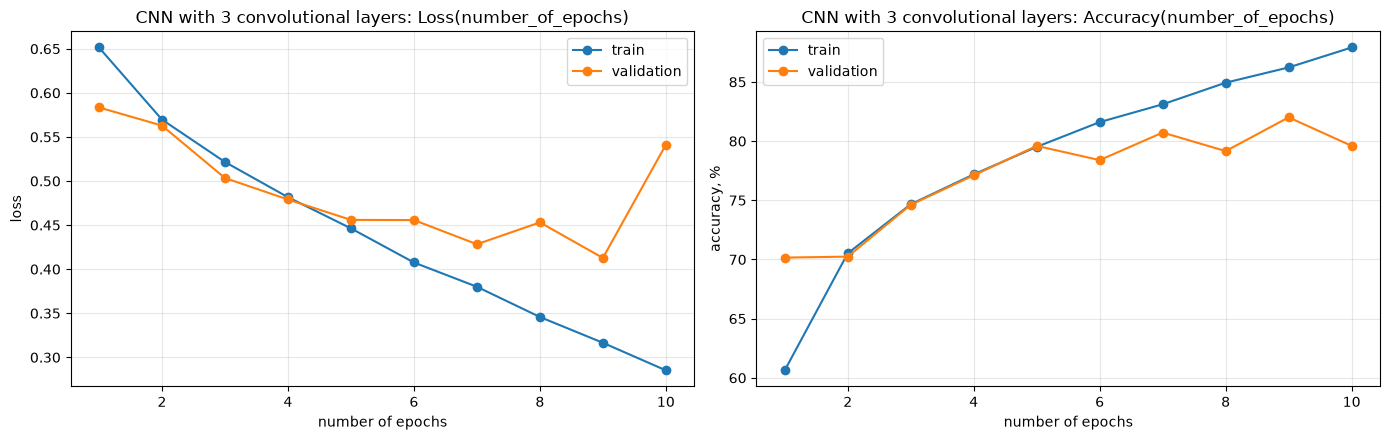

In [10]:
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

    ax[0].plot(epochs, history["train_loss"], marker="o", label="train")
    ax[0].plot(epochs, history["val_loss"], marker="o", label="validation")
    ax[0].set_xlabel("number of epochs")
    ax[0].set_ylabel("loss")
    ax[0].set_title(f"{title}: Loss(number_of_epochs)")
    ax[0].legend()
    ax[0].grid(alpha=0.3)

    ax[1].plot(epochs, history["train_acc"], marker="o", label="train")
    ax[1].plot(epochs, history["val_acc"], marker="o", label="validation")
    ax[1].set_xlabel("number of epochs")
    ax[1].set_ylabel("accuracy, %")
    ax[1].set_title(f"{title}: Accuracy(number_of_epochs)")
    ax[1].legend()
    ax[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_history(history_cnn, "CNN with 3 convolutional layers")

## Task 2. Transfer learning

In [11]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

pretrained_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_dataset_224 = datasets.ImageFolder(train, transform=pretrained_transform)
val_dataset_224   = datasets.ImageFolder(val,   transform=pretrained_transform)
test_dataset_224  = datasets.ImageFolder(test,  transform=pretrained_transform)

train_loader_224 = DataLoader(train_dataset_224, batch_size=batch_size, shuffle=True,  num_workers=num_workers)
val_loader_224   = DataLoader(val_dataset_224,   batch_size=batch_size, shuffle=False, num_workers=num_workers)
test_loader_224  = DataLoader(test_dataset_224,  batch_size=batch_size, shuffle=False, num_workers=num_workers)

print("transfer-learning loaders are ready, input size 224x224")

transfer-learning loaders are ready, input size 224x224


In [ ]:
vgg16_net = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
vgg16_net = vgg16_net.features
for param in vgg16_net.parameters():
    param.requires_grad = False

print(vgg16_net)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

We construct our model of "transfer learning" by adding two fully connected layers to VGG16.

In [ ]:
class VGG16TransferModel(nn.Module):
    def __init__(self, vgg16_features):
        super(VGG16TransferModel, self).__init__()
        self.features = vgg16_features
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))
        self.fc1 = nn.Linear(512 * 7 * 7, 256)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x


vgg_model = VGG16TransferModel(vgg16_net).to(device)

trainable = sum(p.numel() for p in vgg_model.parameters() if p.requires_grad)
frozen = sum(p.numel() for p in vgg_model.parameters() if not p.requires_grad)
print(f"trainable parameters: {trainable:,}")
print(f"frozen (pre-trained) parameters: {frozen:,}")

trainable parameters: 6,423,041
frozen (pre-trained) parameters: 14,714,688


In [ ]:

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(vgg_model.parameters(), lr=1e-5)

In [15]:
num_epochs_transfer = 5

history_vgg = fit(vgg_model, criterion, optimizer, num_epochs_transfer,
                  train_loader_224, val_loader_224, title="VGG16")

VGG16 epoch 1/5 | train loss 0.1044 acc 96.95% | val loss 0.0412 acc 98.67% | 195 s


VGG16 epoch 2/5 | train loss 0.0353 acc 98.86% | val loss 0.0342 acc 98.92% | 184 s


VGG16 epoch 3/5 | train loss 0.0247 acc 99.25% | val loss 0.0322 acc 98.92% | 184 s


VGG16 epoch 4/5 | train loss 0.0181 acc 99.55% | val loss 0.0314 acc 99.00% | 184 s


VGG16 epoch 5/5 | train loss 0.0135 acc 99.73% | val loss 0.0306 acc 99.00% | 188 s


In [ ]:
test_accuracy_vgg = evaluate_accuracy(vgg_model, test_loader_224)
print(f"Accuracy on test data: {test_accuracy_vgg:.2f}%")

Accuracy on test data: 98.80%


Plot the training history for transfer learning:

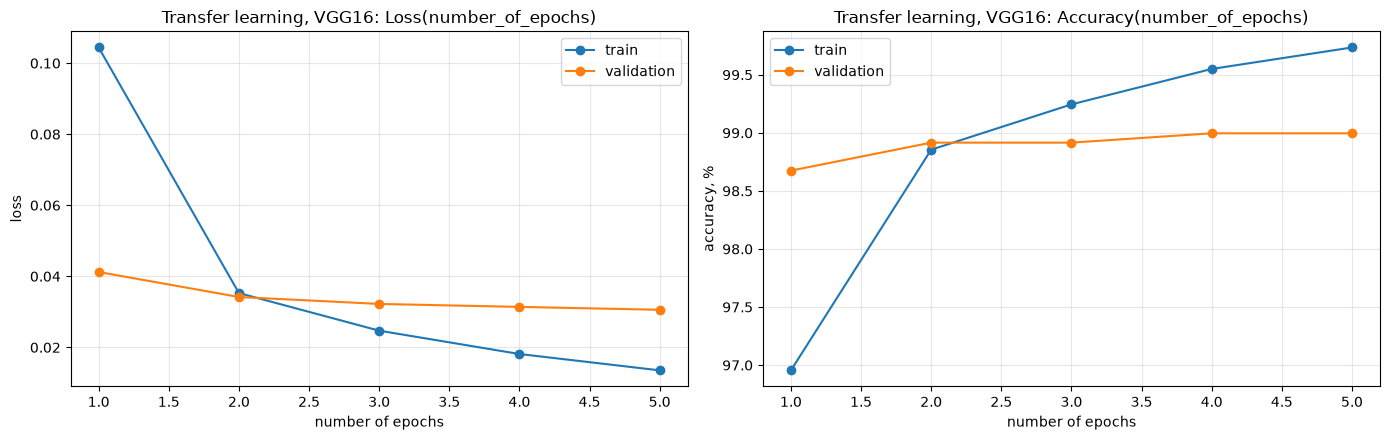

In [17]:
plot_history(history_vgg, "Transfer learning, VGG16")

## Another Transfer Learning model

In [ ]:
resnet_model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in resnet_model.parameters():
    param.requires_grad = False

num_features = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_features, 1)
resnet_model = resnet_model.to(device)

trainable = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)
frozen = sum(p.numel() for p in resnet_model.parameters() if not p.requires_grad)
print(f"trainable parameters: {trainable:,}")
print(f"frozen (pre-trained) parameters: {frozen:,}")

trainable parameters: 513
frozen (pre-trained) parameters: 11,176,512


In [ ]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(resnet_model.fc.parameters(), lr=1e-3)

history_resnet = fit(resnet_model, criterion, optimizer, num_epochs_transfer,
                     train_loader_224, val_loader_224, title="ResNet18")

ResNet18 epoch 1/5 | train loss 0.1676 acc 94.65% | val loss 0.0816 acc 97.71% | 69 s


ResNet18 epoch 2/5 | train loss 0.0843 acc 97.03% | val loss 0.0631 acc 98.07% | 65 s


ResNet18 epoch 3/5 | train loss 0.0743 acc 97.24% | val loss 0.0555 acc 97.87% | 65 s


ResNet18 epoch 4/5 | train loss 0.0681 acc 97.43% | val loss 0.0569 acc 97.91% | 67 s


ResNet18 epoch 5/5 | train loss 0.0654 acc 97.53% | val loss 0.0507 acc 98.03% | 65 s


In [20]:
test_accuracy_resnet = evaluate_accuracy(resnet_model, test_loader_224)
print(f"Accuracy on test data: {test_accuracy_resnet:.2f}%")

Accuracy on test data: 97.60%


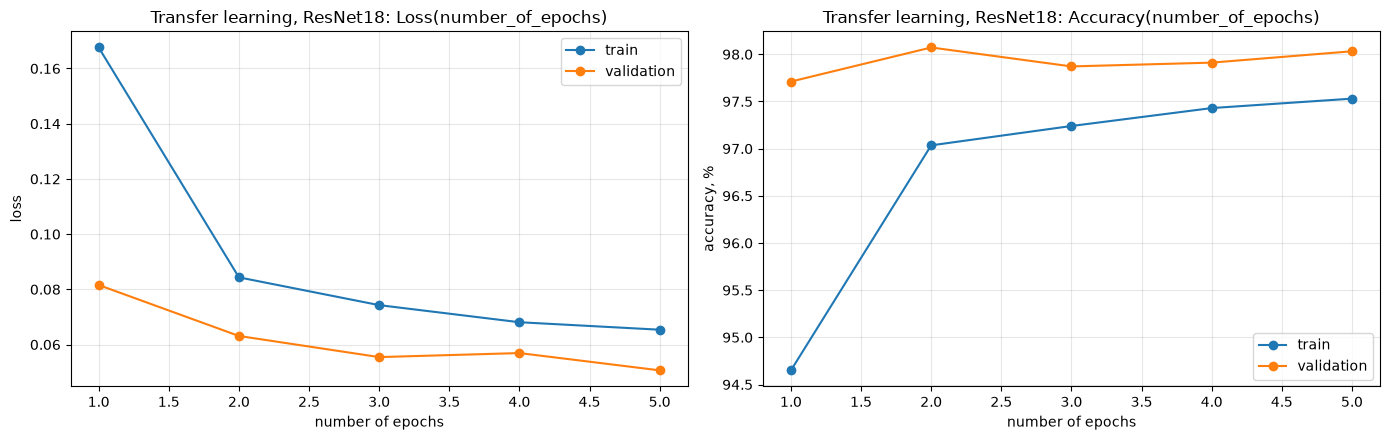

In [21]:
plot_history(history_resnet, "Transfer learning, ResNet18")

In [ ]:
test_accuracies = {
    "CNN from scratch (3 conv layers)": test_accuracy_cnn,
    "Transfer learning, VGG16": test_accuracy_vgg,
    "Transfer learning, ResNet18": test_accuracy_resnet,
}
best_name = max(test_accuracies, key=test_accuracies.get)
print(f"best model on test data: {best_name} ({test_accuracies[best_name]:.2f}%)")

best model on test data: Transfer learning, VGG16 (98.80%)


## Inference on a custom image

The function below takes a path **or a URL**, applies the same preprocessing the model was trained with, and
returns the predicted class with its confidence.

In [ ]:
best_model = {"CNN from scratch (3 conv layers)": model,
              "Transfer learning, VGG16": vgg_model,
              "Transfer learning, ResNet18": resnet_model}[best_name]

best_transform = data_transforms["test"] if best_name.startswith("CNN") else pretrained_transform
class_names = train_dataset.classes


def predict_image(image_path, model=None, device=device, transform=None, show=True):
    model = best_model if model is None else model
    transform = best_transform if transform is None else transform

    if str(image_path).startswith("http"):
        req = urllib.request.Request(image_path, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as response:
            image = Image.open(response).convert("RGB")
    else:
        image = Image.open(image_path).convert("RGB")

    tensor = transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        logit = model(tensor)
        probability_dog = torch.sigmoid(logit).item()

    predicted_class = class_names[1] if probability_dog > 0.5 else class_names[0]
    confidence = probability_dog if probability_dog > 0.5 else 1 - probability_dog

    if show:
        plt.figure(figsize=(3.2, 3.2))
        plt.imshow(image)
        plt.axis("off")
        plt.title(f"{predicted_class} ({confidence * 100:.1f}%)")
        plt.show()

    return predicted_class, confidence

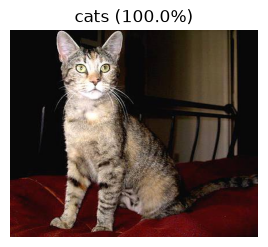

cat.10000.jpg    -> predicted: cats, confidence 100.00%


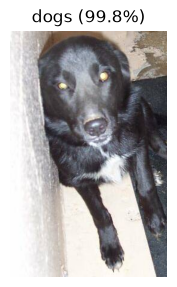

dog.10000.jpg    -> predicted: dogs, confidence 99.75%


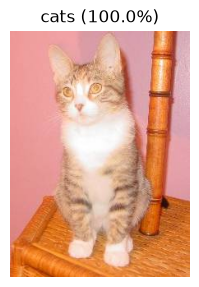

cat.10007.jpg    -> predicted: cats, confidence 100.00%


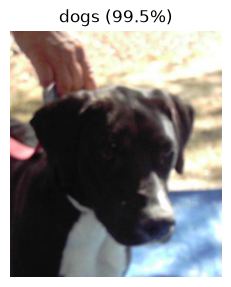

dog.10007.jpg    -> predicted: dogs, confidence 99.48%


In [ ]:
cats = sorted(os.listdir(os.path.join(test, "cats")))
dogs = sorted(os.listdir(os.path.join(test, "dogs")))
samples = [os.path.join(test, "cats", cats[0]), os.path.join(test, "dogs", dogs[0]),
           os.path.join(test, "cats", cats[7]), os.path.join(test, "dogs", dogs[7])]
for path in samples:
    predicted_class, confidence = predict_image(path)
    print(f"{os.path.basename(path):<16} -> predicted: {predicted_class}, confidence {confidence * 100:.2f}%")

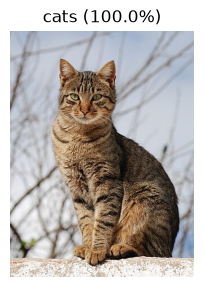

custom photo of a cat -> cats, confidence 100.00%


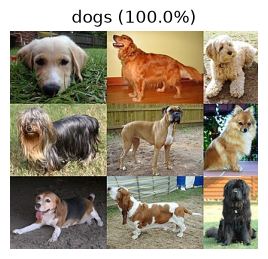

custom photo of dogs -> dogs, confidence 100.00%


In [ ]:
custom_images = {
    "custom photo of a cat": ("data/custom_images/custom_cat.jpg",
                              "https://upload.wikimedia.org/wikipedia/commons/thumb/4/4d/"
                              "Cat_November_2010-1a.jpg/330px-Cat_November_2010-1a.jpg"),
    "custom photo of dogs": ("data/custom_images/custom_dog.jpg",
                             "https://upload.wikimedia.org/wikipedia/commons/thumb/d/d9/"
                             "Collage_of_Nine_Dogs.jpg/330px-Collage_of_Nine_Dogs.jpg"),
}

for description, (local_path, url) in custom_images.items():
    source = local_path if os.path.exists(local_path) else url
    try:
        predicted_class, confidence = predict_image(source)
        print(f"{description} -> {predicted_class}, confidence {confidence * 100:.2f}%")
    except Exception as exc:
        print(f"{description}: image unavailable ({exc}) - pass your own path to predict_image()")